# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Uninformed Search

* Run the code cells from top to bottom with Python 3.
* The visual examples require `networkx` and `matplotlib`.
* Install them with `%pip install networkx matplotlib` if needed.
* The numerical examples use only standard Python.
* Neighbour order determines traversal order when several choices are available.

## Breadth-First Search (BFS)

* **BFS with an adjacency list.**
  * The dictionary lists each node's outgoing neighbours.
  * BFS uses a first-in, first-out (FIFO) queue and marks nodes when they enter the queue, so a node reached through several edges is added only once.

$$
\begin{array}{l}
\hline
\text{Algorithm: Breadth-First Search (BFS)}\\
\hline
\text{Input: Graph } G \text{ and start node } s\\
\text{Output: Traversal order of all reachable nodes}\\[4pt]
1.\quad visited \gets \{s\},\quad order \gets [\,]\\
2.\quad Q \gets \text{a FIFO queue containing } s\\
3.\quad \text{while } Q \neq \varnothing \text{ do}\\
4.\quad \qquad current \gets \mathrm{Dequeue}(Q)\\
5.\quad \qquad \text{append } current \text{ to } order\\
6.\quad \qquad \text{for each successor } neighbor \text{ of } current \text{ do}\\
7.\quad \qquad \qquad \text{if } neighbor \notin visited \text{ then}\\
8.\quad \qquad \qquad \qquad \text{add } neighbor \text{ to } visited\\
9.\quad \qquad \qquad \qquad \mathrm{Enqueue}(Q,neighbor)\\
10.\quad \qquad \qquad \text{end if}\\
11.\quad \qquad \text{end for}\\
12.\quad \text{end while}\\
13.\quad \text{return } order\\
\hline
\end{array}
$$

In [ ]:
graph = {
  '1' : ['2', '3','4'],
  '2' : ['5'],
  '3' : ['6'],
  '4' : ['6'],
  '5' : ['7'],
  '6' : ['7'],
  '7' : []
}
visited = []
queue = []

def bfs(visited, graph, node):
  visited.append(node)
  queue.append(node)
  while queue:          #visiting all nodes one by one
    m = queue.pop(0)
    print (m, end = " ")
    for neighbour in graph[m]:
      if neighbour not in visited:
        visited.append(neighbour)
        queue.append(neighbour)
print("Breadth-First Search")
bfs(visited, graph, '1')

Breadth-First Search
1 2 3 4 5 6 7 

* The output `1 2 3 4 5 6 7` is the nodes that are processed level by level, in the listed neighbour order.
* This is a traversal, not a single route; BFS finds minimum-edge paths when parent links are recorded.
* Here, `pop(0)` and list membership are linear-time operations, and the global queue must be reset before another call; the next example uses `deque` and a set.

* **Visualize BFS and recover a path.**
  * This example uses NetworkX to represent an undirected tree, `deque.popleft()` to remove the oldest queued node, and a parent dictionary to record each node's first discovery.
  * After the full traversal, it reconstructs the route to `K` by following parent links backward.

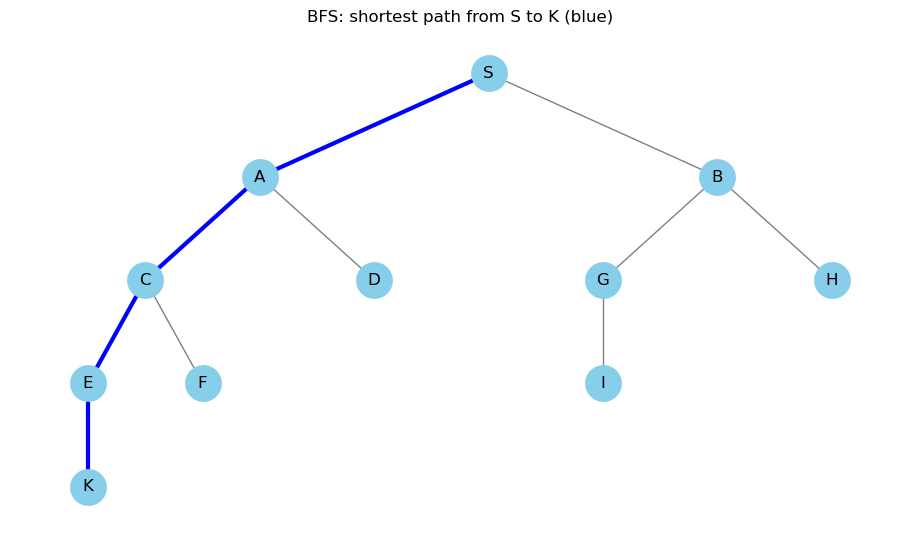

BFS traversal order: S -> A -> B -> C -> D -> G -> H -> E -> F -> I -> K
Shortest path from S to K: S -> A -> C -> E -> K


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

def bfs_tree(graph, start):
    visited = {start}
    queue = deque([start])
    order = []
    parent = {start: None}
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbour in graph[node]:
            if neighbour not in visited:
                visited.add(neighbour)
                parent[neighbour] = node
                queue.append(neighbour)
    return order, parent

G = nx.Graph()
edges = [('S', 'A'), ('S', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'G'),
         ('B', 'H'), ('C', 'E'), ('C', 'F'), ('G', 'I'), ('E', 'K')]
G.add_edges_from(edges)
order, parent = bfs_tree(G, 'S')
path = []
node = 'K'
while node is not None:
    path.append(node)
    node = parent[node]
path.reverse()

# Fixed positions show the tree without requiring Graphviz.
pos = {'S': (0, 0), 'A': (-2, -1), 'B': (2, -1),
       'C': (-3, -2), 'D': (-1, -2), 'G': (1, -2), 'H': (3, -2),
       'E': (-3.5, -3), 'F': (-2.5, -3), 'I': (1, -3), 'K': (-3.5, -4)}
plt.figure(figsize=(9, 5))
nx.draw(G, pos, with_labels=True, node_size=650, node_color='skyblue', edge_color='gray')
nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])), edge_color='blue', width=3)
plt.title('BFS: shortest path from S to K (blue)')
plt.show()
print('BFS traversal order:', ' -> '.join(order))
print('Shortest path from S to K:', ' -> '.join(path))

**Order versus path.**
  * The traversal is `S -> A -> B -> C -> D -> G -> H -> E -> F -> I -> K`, whereas the blue path is `S -> A -> C -> E -> K` (four edges).
  * Consecutive nodes in a traversal need not share an edge.
  * BFS guarantees a minimum-edge path in an unweighted graph, but not a minimum-cost path when edge costs differ.

## Depth-First Search (DFS)

**Recursive DFS on a tree:**
  * DFS explores an unvisited neighbour recursively before returning to try the next neighbour.
  * The visited set prevents revisits, the call stack supports backtracking, and the parent dictionary records the discovery edges used to reconstruct a path.

$$
\begin{array}{l}
\hline
\text{Algorithm: Depth-First Search (DFS) with Path Reconstruction}\\
\hline
\text{Input: Graph } G,\text{ start node } s,\text{ goal node } t\\
\text{Output: Traversal order and a discovered path, or } \mathrm{None}\\[4pt]
1.\quad \text{function } \mathrm{DFS}(G,node,visited,order,parent)\\
2.\quad \qquad \text{add } node \text{ to } visited\\
3.\quad \qquad \text{append } node \text{ to } order\\
4.\quad \qquad \text{for each successor } neighbor \text{ of } node \text{ do}\\
5.\quad \qquad \qquad \text{if } neighbor \notin visited \text{ then}\\
6.\quad \qquad \qquad \qquad parent[neighbor] \gets node\\
7.\quad \qquad \qquad \qquad \mathrm{DFS}(G,neighbor,visited,order,parent)\\
8.\quad \qquad \qquad \text{end if}\\
9.\quad \qquad \text{end for}\\
10.\quad \text{end function}\\[4pt]
11.\quad visited \gets \varnothing,\quad order \gets [\,]\\
12.\quad parent[s] \gets \mathrm{None}\\
13.\quad \mathrm{DFS}(G,s,visited,order,parent)\\
14.\quad path \gets \mathrm{None}\\
15.\quad \text{if } t \in visited \text{ then}\\
16.\quad \qquad path \gets [\,],\quad node \gets t\\
17.\quad \qquad \text{while } node \neq \mathrm{None} \text{ do}\\
18.\quad \qquad \qquad \text{append } node \text{ to } path\\
19.\quad \qquad \qquad node \gets parent[node]\\
20.\quad \qquad \text{end while}\\
21.\quad \qquad path \gets \mathrm{Reverse}(path)\\
22.\quad \text{end if}\\
23.\quad \text{return } (order,path)\\
\hline
\end{array}
$$

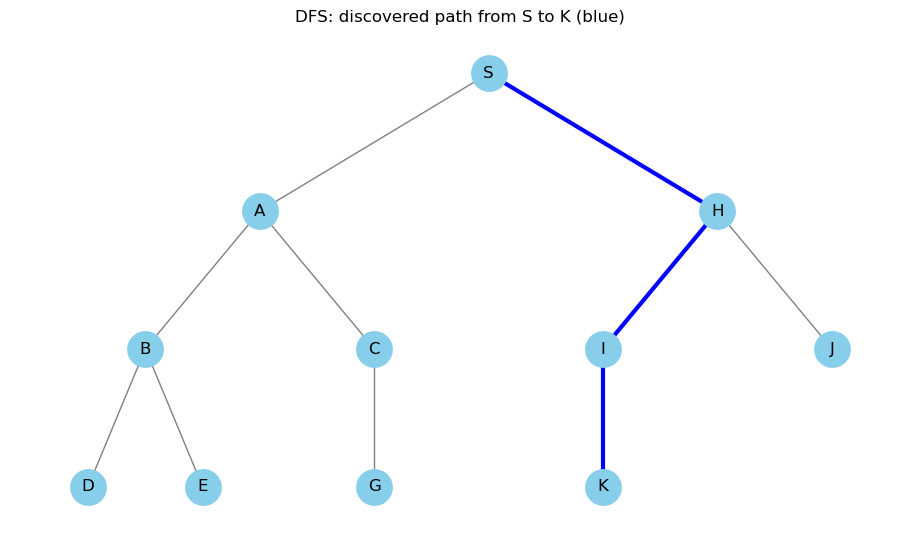

DFS traversal order: S -> A -> B -> D -> E -> C -> G -> H -> I -> K -> J
Discovered path from S to K: S -> H -> I -> K


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

def dfs_tree(graph, node, visited, order, parent):
    visited.add(node)
    order.append(node)
    for neighbour in graph[node]:
        if neighbour not in visited:
            parent[neighbour] = node
            dfs_tree(graph, neighbour, visited, order, parent)

G = nx.Graph()
edges = [('S', 'A'), ('S', 'H'), ('A', 'B'), ('A', 'C'), ('B', 'D'),
         ('B', 'E'), ('C', 'G'), ('H', 'I'), ('H', 'J'), ('I', 'K')]
G.add_edges_from(edges)
order = []
parent = {'S': None}
dfs_tree(G, 'S', set(), order, parent)
path = []
node = 'K'
while node is not None:
    path.append(node)
    node = parent[node]
path.reverse()

pos = {'S': (0, 0), 'A': (-2, -1), 'H': (2, -1),
       'B': (-3, -2), 'C': (-1, -2), 'I': (1, -2), 'J': (3, -2),
       'D': (-3.5, -3), 'E': (-2.5, -3), 'G': (-1, -3), 'K': (1, -3)}
plt.figure(figsize=(9, 5))
nx.draw(G, pos, with_labels=True, node_size=650, node_color='skyblue', edge_color='gray')
nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])), edge_color='blue', width=3)
plt.title('DFS: discovered path from S to K (blue)')
plt.show()
print('DFS traversal order:', ' -> '.join(order))
print('Discovered path from S to K:', ' -> '.join(path))

**DFS backtracking.**
  * The traversal is `S -> A -> B -> D -> E -> C -> G -> H -> I -> K -> J`;
  * The blue route to `K` is `S -> H -> I -> K`. DFS continues through the whole tree in this example, even after visiting `K`.
  * A tree has only one simple path between two nodes; on a general graph, DFS does not guarantee a shortest path.

**DFS with an adjacency list.**
  * This compact version prints each node at its first visit and stores it in a set.
  * Neighbours are explored in list order, and recursion returns to earlier nodes when no unvisited neighbour remains.

In [ ]:
#DFS
graph = {
  '1' : ['2', '3','4'],
  '2' : ['5'],
  '3' : ['6'],
  '4' : ['6'],
  '5' : ['7'],
  '6' : ['7'],
  '7' : []
}

visited = set()

def dfs(visited, graph, node):
    if node not in visited:
        print (node)
        visited.add(node)
        for neighbour in graph[node]:
            dfs(visited, graph, neighbour)

print("Following is the Depth-First Search")
dfs(visited, graph, '1')

Following is the Depth-First Search
1
2
5
7
3
6
4


**Follow the recursion.**
  * The output is `1, 2, 5, 7, 3, 6, 4`, with one node per line. Node `7` is not printed again when reached from `6`, because it is already visited.
  * With adjacency lists and expected constant-time set membership, this traversal takes $O(V+E)$ time over the reachable graph; very deep graphs can exceed Python's recursion limit.

## **Iterative Deepening Search (IDS)**

* IDS repeats depth-limited DFS with limits of 0, 1, 2, and so on, up to the inclusive `max_depth`.
* Each attempt starts afresh; the current path prevents cycles, and a successful call returns the actual route rather than an exploration log.

$$
\begin{array}{l}
\hline
\text{Algorithm: Iterative Deepening Search (IDS)}\\
\hline
\text{Input: Graph } G,\text{ start node } s,\text{ goal node } t,\text{ maximum depth } D\\
\text{Output: A discovered path within depth } D,\text{ or } \mathrm{None}\\[4pt]
1.\quad \text{function } \mathrm{DLS}(G,current,t,remaining,path)\\
2.\quad \qquad \text{if } current=t \text{ then}\\
3.\quad \qquad \qquad \text{return } path\\
4.\quad \qquad \text{end if}\\
5.\quad \qquad \text{if } remaining=0 \text{ then}\\
6.\quad \qquad \qquad \text{return } \mathrm{None}\\
7.\quad \qquad \text{end if}\\
8.\quad \qquad \text{for each successor } neighbor \text{ of } current \text{ do}\\
9.\quad \qquad \qquad \text{if } neighbor \notin path \text{ then}\\
10.\quad \qquad \qquad \qquad result \gets \mathrm{DLS}(G,neighbor,t,remaining-1,path+[neighbor])\\
11.\quad \qquad \qquad \qquad \text{if } result \neq \mathrm{None} \text{ then}\\
12.\quad \qquad \qquad \qquad \qquad \text{return } result\\
13.\quad \qquad \qquad \qquad \text{end if}\\
14.\quad \qquad \qquad \text{end if}\\
15.\quad \qquad \text{end for}\\
16.\quad \qquad \text{return } \mathrm{None}\\
17.\quad \text{end function}\\[4pt]
18.\quad \text{function } \mathrm{IDS}(G,s,t,D)\\
19.\quad \qquad \text{for } limit \gets 0 \text{ to } D \text{ do}\\
20.\quad \qquad \qquad result \gets \mathrm{DLS}(G,s,t,limit,[s])\\
21.\quad \qquad \qquad \text{if } result \neq \mathrm{None} \text{ then}\\
22.\quad \qquad \qquad \qquad \text{return } result\\
23.\quad \qquad \qquad \text{end if}\\
24.\quad \qquad \text{end for}\\
25.\quad \qquad \text{return } \mathrm{None}\\
26.\quad \text{end function}\\
\hline
\end{array}
$$

In [ ]:
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['G'],
    'D': [],
    'E': ['F'],
    'G': [],
    'F': []
}

def depth_limited_search(graph, current, goal, remaining_depth, path):
    print('Checking for destination', current)
    if current == goal:
        return path.copy()
    if remaining_depth == 0:
        return None
    for neighbour in graph[current]:
        if neighbour not in path:  # Avoid cycles within the current path.
            result = depth_limited_search(
                graph, neighbour, goal, remaining_depth - 1, path + [neighbour]
            )
            if result is not None:
                return result
    return None

def iterative_deepening_search(graph, start, goal, max_depth):
    for limit in range(max_depth + 1):  # Include max_depth; root depth is zero.
        print(f'\nDepth limit: {limit}')
        result = depth_limited_search(graph, start, goal, limit, [start])
        if result is not None:
            return result
    return None

path = iterative_deepening_search(graph, 'A', 'G', max_depth=4)
if path is None:
    print('No path found within the depth limit.')
else:
    print('A path exists:', ' -> '.join(path))


Depth limit: 0
Checking for destination A

Depth limit: 1
Checking for destination A
Checking for destination B
Checking for destination C

Depth limit: 2
Checking for destination A
Checking for destination B
Checking for destination D
Checking for destination E
Checking for destination C
Checking for destination G
A path exists: A -> C -> G


* The checks are `A` at limit 0; `A, B, C` at limit 1; and `A, B, D, E, C, G` at limit 2.
* The returned path is `A -> C -> G`.
* Repeated visits across iterations are intentional: IDS finds a shallowest goal when the bound is sufficient, and this is cost-optimal only when all step costs are equal.
* Failure here means no path was found within the chosen bound.

## **Uniform-Cost Search (UCS)**

* UCS expands the frontier entry with the smallest accumulated cost $g(n)$, not the smallest depth.
* `heapq.heappush` maintains a min-heap and `heapq.heappop` removes its minimum; tuples compare their first element (`cost`) first, while `Node.__lt__` handles comparisons if those costs tie.
* This implementation requires nonnegative edge costs.

$$
\begin{array}{l}
\hline
\text{Algorithm: Uniform-Cost Search (UCS)}\\
\hline
\text{Input: Graph } G,\text{ nonnegative edge costs } c,\text{ start node } s,\text{ goal node } t\\
\text{Output: Minimum path cost, or } \infty\\[4pt]
1.\quad visited \gets \varnothing\\
2.\quad Q \gets \text{a min-priority queue containing } (0,s)\\
3.\quad \text{while } Q \neq \varnothing \text{ do}\\
4.\quad \qquad (cost,current) \gets \mathrm{PopMin}(Q)\\
5.\quad \qquad \text{if } current \in visited \text{ then}\\
6.\quad \qquad \qquad \text{continue}\\
7.\quad \qquad \text{end if}\\
8.\quad \qquad \text{add } current \text{ to } visited\\
9.\quad \qquad \text{if } current=t \text{ then}\\
10.\quad \qquad \qquad \text{return } cost\\
11.\quad \qquad \text{end if}\\
12.\quad \qquad \text{for each successor } neighbor \text{ of } current \text{ do}\\
13.\quad \qquad \qquad \text{if } neighbor \notin visited \text{ then}\\
14.\quad \qquad \qquad \qquad newCost \gets cost+c(current,neighbor)\\
15.\quad \qquad \qquad \qquad \mathrm{Push}(Q,(newCost,neighbor))\\
16.\quad \qquad \qquad \text{end if}\\
17.\quad \qquad \text{end for}\\
18.\quad \text{end while}\\
19.\quad \text{return } \infty\\
\hline
\end{array}
$$

In [ ]:
import heapq
class Node:
    def __init__(self, name, cost):
        self.name = name
        self.cost = cost
    def __lt__(self, other):
        return self.cost < other.cost
def uniform_cost_search(graph, start, goal):
    visited = set()
    priority_queue = [(0, Node(start, 0))]
    while priority_queue:
        cost, current_node = heapq.heappop(priority_queue)
        if current_node.name in visited:
            continue
        visited.add(current_node.name)
        if current_node.name == goal:
            return cost
        for neighbor, neighbor_cost in graph[current_node.name]:
            if neighbor not in visited:
                heapq.heappush(priority_queue, (cost + neighbor_cost, Node(neighbor, cost + neighbor_cost)))
    return float('inf')

graph = {
    'S': [('A', 1), ('B', 4)],
    'A': [('C', 3), ('D', 2)],
    'B': [('G', 5)],
    'C': [('E', 5)],
    'E': [('G', 5)],
    'D': [('G', 3)],
    'G': []
}
start_node = 'S'
goal_node = 'G'
result = uniform_cost_search(graph, start_node, goal_node)
if result != float('inf'):
    print(f"The cost of the cheapest path from {start_node} to {goal_node} is {result}.")
else:
    print(f"There is no path from {start_node} to {goal_node}.")

The cost of the cheapest path from S to G is 6.


* The printed result is `6`, achieved by `S -> A -> D -> G` with cost $1+2+3$. The function returns only the cost, not the route.
* A node is finalized when removed from the heap, and later duplicate entries are skipped; the goal is accepted at removal, not at first discovery, which is essential for UCS optimality.